# Lab 9 – Reentrenamiento mensual (Persona A, CP5; sección 4)
Se repite la prueba reentrenando al inicio de cada mes (1-oct, 1-nov y 1-dic, **ventana expansiva**: todos los datos con `ds < origen`) con `common.backtest(modelo, panel, retrain="monthly")`. Script: `run_reentreno.py`.
- **Deep learning**: MLP de A (mejor de sus modelos PyTorch por MASE de **validación**). Si el mejor modelo de B (LSTM, N-HiTS, ...) supera al MLP en validación, hay que repetir esto con ese modelo; el script está parametrizado por `RetrainableTorch`.
- **Contraste no profundo**: LightGBM global (mismo número de árboles e hiperparámetros que el modelo fijo).
- **Baselines estadísticos** (Naive, seasonal naive, MSTL): ya se reajustan en **cada origen** con las últimas 8 semanas, es decir, son más adaptativos que un reentrenamiento mensual; por eso no tiene sentido repetirlos.
- Cada reentrenamiento parte de pesos nuevos y repite las mismas épocas; el escalador no cambia (así se aísla el efecto de los pesos).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
panel = C.load_panel(); scale = C.mase_scales(panel)
rows = []
for base in ("mlp", "lightgbm_global"):
    for tag, name in (("fijo (1 entrenamiento)", base), ("mensual (3 reentrenos)", base + "_reentreno")):
        p = pd.read_parquet(C.PRED_DIR / f"{name}.parquet").merge(panel, on=["unique_id", "ds"])
        g = C._agg(p, scale); row = {"modelo": base, "protocolo": tag, "MAE": g["MAE"], "RMSE": g["RMSE"], "WAPE": g["WAPE"], "MASE": g["MASE"]}
        for m, nm in ((10, "oct"), (11, "nov"), (12, "dic")): row[f"MASE_{nm}"] = C._agg(p[p.ds.dt.month == m], scale)["MASE"]
        row["MASE_22_28dic"] = C._agg(p[p.ds.between(*C.XMAS)], scale)["MASE"]
        rows.append(row)
tab = pd.DataFrame(rows).set_index(["modelo", "protocolo"]); display(tab.round(4))

MAE      RMSE    WAPE    MASE  \
modelo          protocolo                                                   
mlp             fijo (1 entrenamiento)  37.4969  175.6836  0.0695  0.8927   
                mensual (3 reentrenos)  36.8781  182.9288  0.0684  0.8748   
lightgbm_global fijo (1 entrenamiento)  33.9263  164.6167  0.0629  0.8499   
                mensual (3 reentrenos)  33.7638  166.9507  0.0626  0.8485   

                                        MASE_oct  MASE_nov  MASE_dic  \
modelo          protocolo                                              
mlp             fijo (1 entrenamiento)    0.8461    0.7503    1.0772   
                mensual (3 reentrenos)    0.8570    0.7200    1.0425   
lightgbm_global fijo (1 entrenamiento)    0.7893    0.7325    1.0242   
                mensual (3 reentrenos)    0.7893    0.7330    1.0196   

                                        MASE_22_28dic  
modelo          protocolo                              
mlp             fijo (1 entrenamiento)         1.6360  
                mensual (3 reentrenos)         1.5969  
lightgbm_global fijo (1 entrenamiento)         1.5421  
                mensual (3 reentrenos)         1.5429

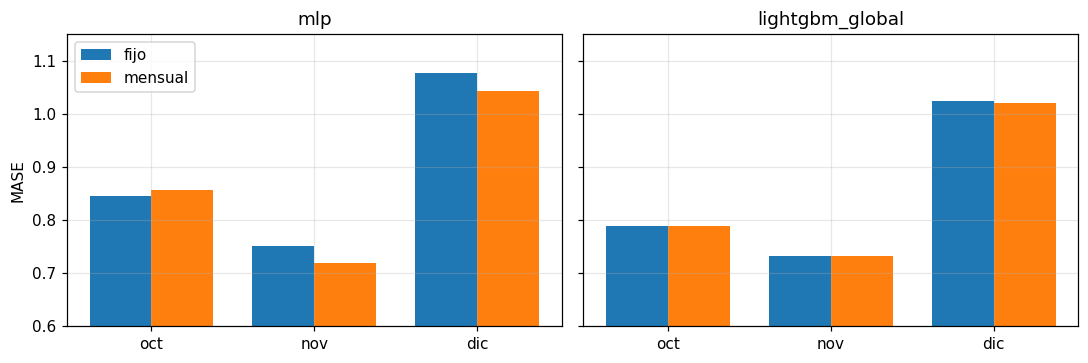

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, base in zip(axs, ("mlp", "lightgbm_global")):
    t = tab.loc[base][["MASE_oct", "MASE_nov", "MASE_dic"]]
    x = np.arange(3); w = .38
    ax.bar(x - w/2, t.iloc[0], w, label="fijo"); ax.bar(x + w/2, t.iloc[1], w, label="mensual")
    ax.set_xticks(x, ["oct", "nov", "dic"]); ax.set_title(base); ax.set_ylim(.6, 1.15)
axs[0].set_ylabel("MASE"); axs[0].legend(); plt.tight_layout(); plt.savefig("figs/reentreno_A.png"); plt.show()

In [3]:
# Comprobación del protocolo: en octubre el reentrenamiento usa EXACTAMENTE los mismos datos que el modelo fijo
for base in ("lightgbm_global", "mlp"):
    a, b = (pd.read_parquet(C.PRED_DIR / f"{n}.parquet") for n in (base, base + "_reentreno"))
    m = a.ds.dt.month == 10
    print(base, "| octubre: máx |diferencia| de pronóstico (kWh) =", float(np.abs(a[m].y_hat.values - b[m].y_hat.values).max()))

lightgbm_global | octubre: máx |diferencia| de pronóstico (kWh) = 0.0
mlp | octubre: máx |diferencia| de pronóstico (kWh) = 781.6583538559626


**Lectura.**
- **¿Cambia el error?** Poco. En LightGBM el MASE pasa de 0.8499 a 0.8485 y el de noviembre y diciembre cambia ±0.005; en el MLP pasa de 0.8927 a 0.8748 (WAPE 6.95 % → 6.84 %), con mejora en noviembre (−0.030) y diciembre (−0.035).
- **RMSE.** Empeora algo en ambos modelos (MLP 175.7 → 182.9; LightGBM 164.6 → 167.0 kWh) aunque MAE y MASE mejoran o se mantienen: reentrenar no reduce los errores más grandes, que dominan el RMSE.
- **Cuánto de eso es señal.** En octubre los dos protocolos usan los mismos datos: LightGBM da **exactamente** lo mismo (diferencia 0.0, el protocolo está bien), pero el MLP no (MASE 0.846 vs 0.857, con pronósticos que difieren hasta cientos de kWh en clientes grandes): reentrenar la red desde cero con la misma semilla no reproduce los pesos en la GPU (MPS). Esa diferencia de ±0.01 en octubre es el orden del ruido entre entrenamientos, así que la mejora del MLP en noviembre y diciembre (0.03) es algo mayor que ese ruido pero con **una sola corrida** no la tratamos como concluyente.
- **Interpretación.** Reentrenar ayuda más al modelo con más capacidad (MLP) y casi nada a LightGBM, y la ganancia aparece en los meses más lejanos al corte de entrenamiento (noviembre y diciembre), como era de esperar si hay deriva. El costo es 3 entrenamientos en lugar de 1 (≈ 70 s cada uno para el MLP en GPU).
- La semana de Navidad sigue siendo la más difícil en ambos protocolos: ningún reentrenamiento (hasta el 30-nov) ve datos de diciembre, así que no puede aprender el cambio de régimen de esa semana.